### Zadania

Celem listy jest zbadanie działania metod binaryzacji obrazów w skali szarości i kolorowych. Dążymy do wyobrębnienia obiektów znajdujących się na podanych obrazach, tzn. uzyskania separacji obiektów od tła, a także oddzielenia poszczególnych obiektów. Natomiast samo osiągnięcie "jakiegoś" wyniku ([`cv2.threshold`](https://docs.opencv.org/3.4/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57) odpalone, próg wybrany "z palca", _coś tam_ wychodzi, wynik wyświetlony) to co najwyżej połowa sukcesu i oceny. Ważne jest przeprowadzenie eksperymentów wyjaśniających dobór parametrów.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

##### Zad. 1: Monety szare

Dane są dwa czarno-białe obrazy monet, `monety_szare` oraz `monety_szare_szum`, z których drugi zawiera pewien poziom zakłóceń. Dokonaj binaryzacji tych obrazów za pomocą progowania.  
A. Jak wartość progu wpływa na wyniki?  
B. Jaki wpływ mają zakłócenia w drugim obrazie? Zastosuj wybraną metodę odszumiania i przeanalizuj efekty.

In [3]:
monety_szare = cv2.imread('../Materialy/Monety_szare.bmp',cv2.IMREAD_GRAYSCALE)
monety_szum = cv2.imread('../Materialy/Monety_szare_szum.bmp',cv2.IMREAD_GRAYSCALE)

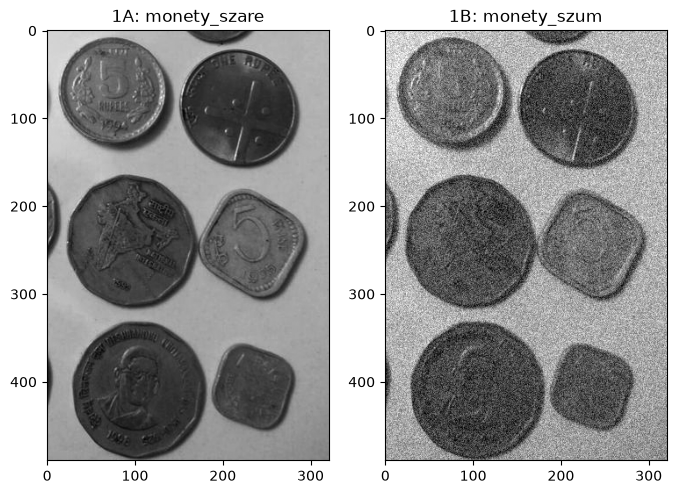

In [4]:
_, (a, b) = plt.subplots(1,2, figsize=(8,6))
a.imshow(monety_szare, cmap='gray')
a.title.set_text('1A: monety_szare')
b.imshow(monety_szum, cmap='gray')
b.title.set_text('1B: monety_szum')

Rozwiązanie części 1A:

In [5]:
def get_threshold_image(image, threshold):
    # Create a binary image based on the threshold
    _, binary_image = cv2.threshold(image, threshold, 255, cv2.THRESH_BINARY)
    return Image.fromarray(binary_image)

def show_threshold_images(image, thresholds):
    _, axes = plt.subplots(1, len(thresholds), figsize=(15, 5))
    for ax, threshold in zip(axes, thresholds):
        threshold_image = get_threshold_image(image, threshold)
        ax.imshow(threshold_image, cmap='gray')
        ax.set_title(f'Threshold: {threshold}')
        ax.axis('off')
    plt.show()

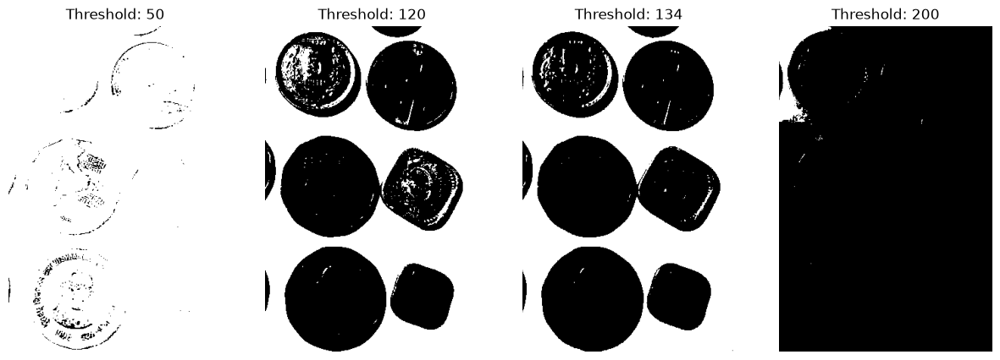

In [35]:
thresholds = [50, 120, 134, 200]

show_threshold_images(monety_szare, thresholds)

Wartość progu wpływa na to, które piksele zostaną sklasyfikowane jako białe (obiekty) 
a które jako czarne (tło). 

- Niska wartość progu: Więcej pikseli zostaje zaklasyfikowanych jako białe, 
  znikanie obiektów z zachowaniem niektórych szczegółów na obiektach.
  
- Średnia wartość progu: Monety są dobrze widoczne z dobrą 
  separacją od tła.
  
- Wysoka wartość progu: Mniej pikseli spełnia warunek (pixel > próg), 
  więcej pikseli zostaje zaklasyfikowanych jako czarne. Tracimy szczegóły, 
  aż całe obiekty mogą zniknąć.

Rozwiązanie części 1B:


Text(0, 0.5, 'Frequency')

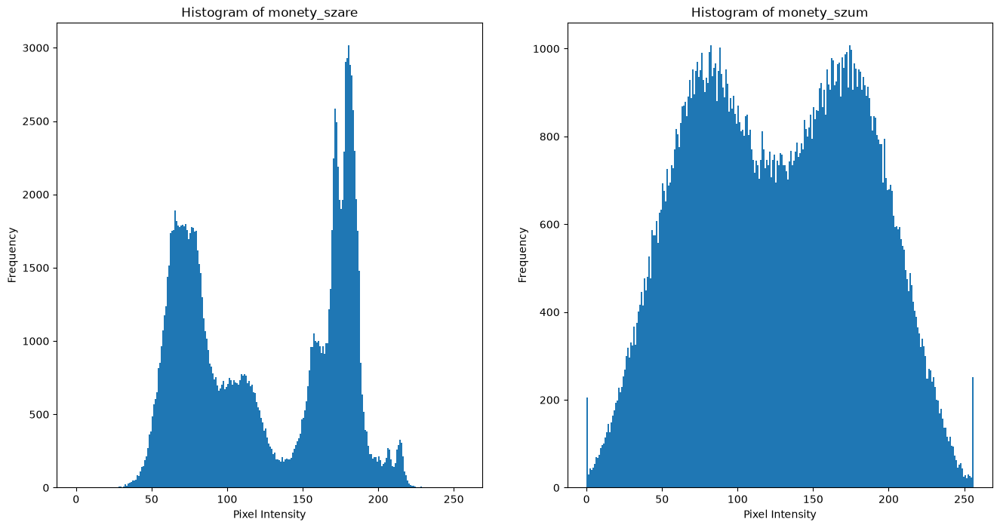

In [7]:
_, (a, b) = plt.subplots(1,2, figsize=(16,8))

a.hist(monety_szare.flatten(), bins=256, range=(0, 256))
a.set_title('Histogram of monety_szare')
a.set_xlabel('Pixel Intensity')
a.set_ylabel('Frequency')

b.hist(monety_szum.flatten(), bins=256, range=(0, 256))
b.set_title('Histogram of monety_szum')
b.set_xlabel('Pixel Intensity')
b.set_ylabel('Frequency')

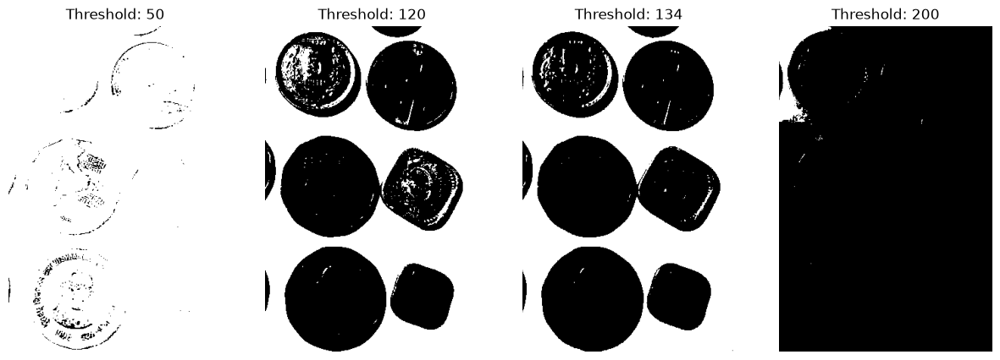

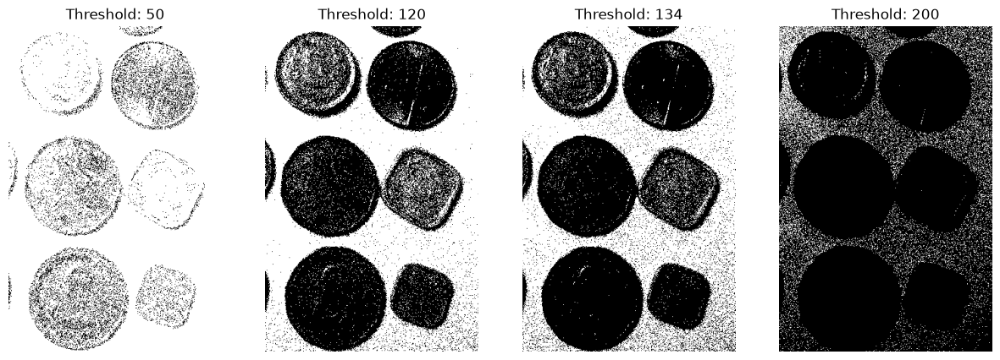

In [36]:
thresholds = [50, 120, 134, 200]

show_threshold_images(monety_szare, thresholds)
show_threshold_images(monety_szum, thresholds)

Szum rozmywa histogram, więc garby tła i monet zachodzą na siebie. Żaden próg nie oddziela ich czysto i w binaryzacji pojawiają się pojedyncze błędne piksele zarówno w tle, jak i na monetach.

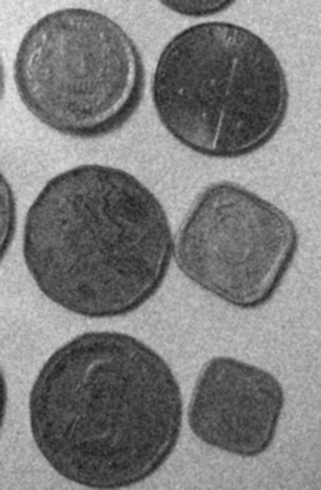

In [9]:
denoised_image = cv2.GaussianBlur(monety_szum, (5, 5), 0)
Image.fromarray(denoised_image)

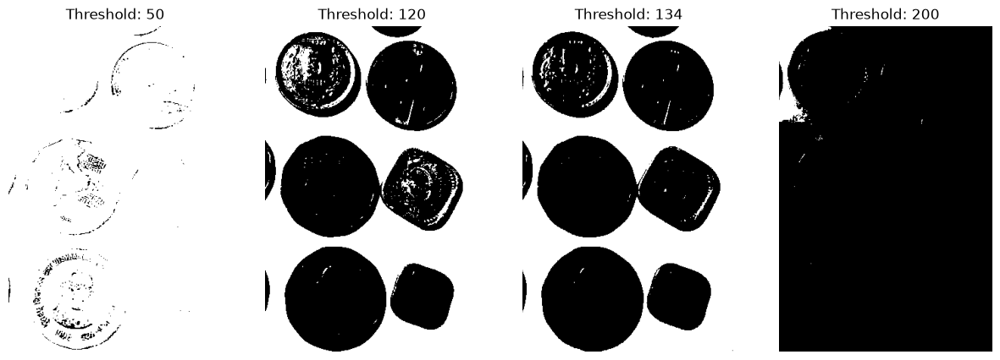

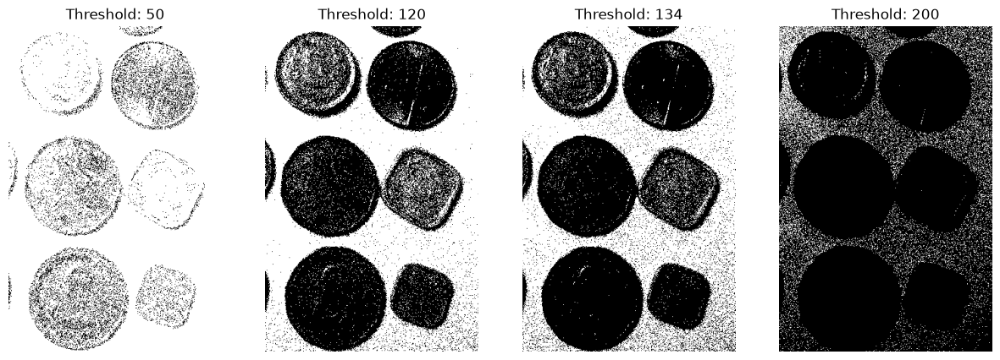

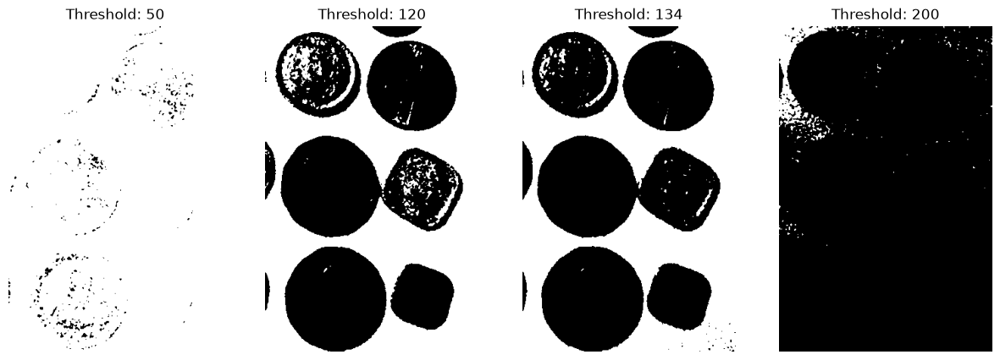

In [37]:
thresholds = [50, 120, 134, 200]

show_threshold_images(monety_szare, thresholds)
show_threshold_images(monety_szum, thresholds)
show_threshold_images(denoised_image, thresholds)

Text(0, 0.5, 'Frequency')

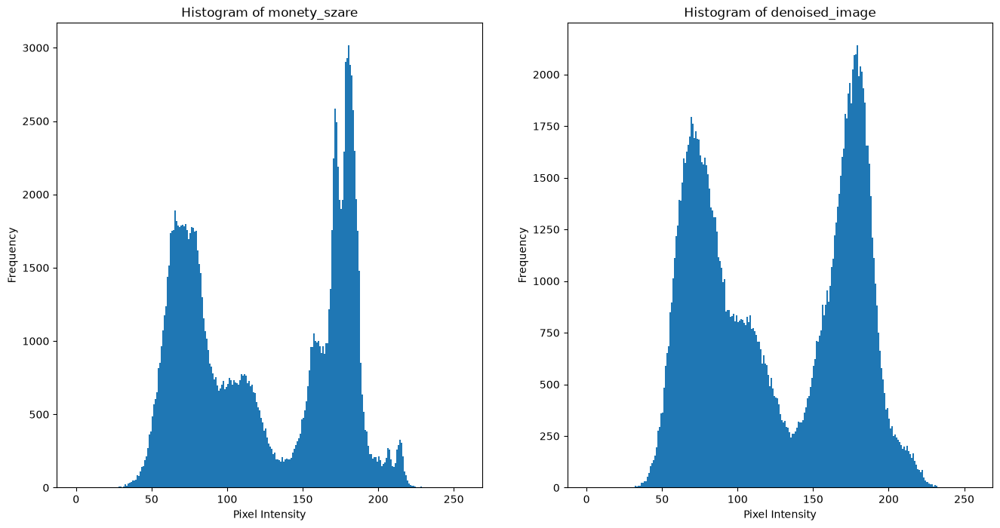

In [11]:
_, (a, b) = plt.subplots(1,2, figsize=(16,8))

a.hist(monety_szare.flatten(), bins=256, range=(0, 256))
a.set_title('Histogram of monety_szare')
a.set_xlabel('Pixel Intensity')
a.set_ylabel('Frequency')

b.hist(denoised_image.flatten(), bins=256, range=(0, 256))
b.set_title('Histogram of denoised_image')
b.set_xlabel('Pixel Intensity')
b.set_ylabel('Frequency')

Binaryzacja odszumionego obrazka jest prawie identyczna co binaryzacja obrazka bez szumu.

##### Zad. 2: Monety kolorowe

Na podobnej zasadzie dokonaj binaryzacji poniższego obrazu kolorowego.  
Skorzystaj z modelu barw HSV. Uzasadnij dobór kanału oraz progu binaryzacji.

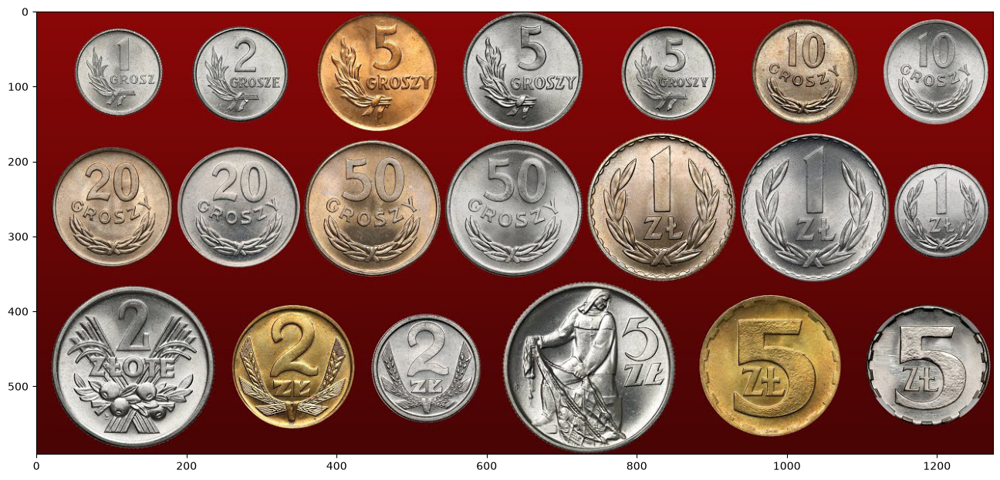

In [12]:
monety_kolor = cv2.imread('../Materialy/Monety_kolor.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor[..., ::-1]);

Text(0.5, 1.0, 'Value')

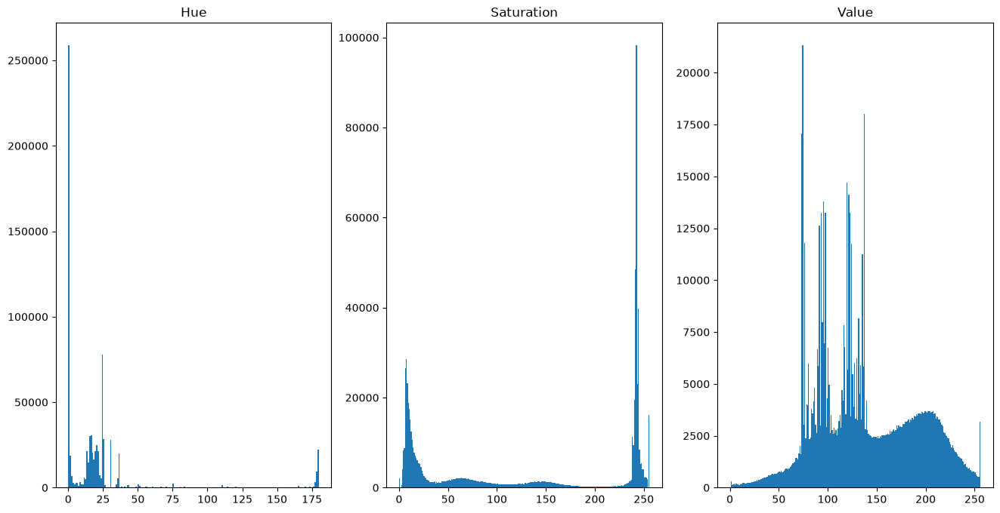

In [13]:
image_hsv = cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2HSV)

_, (h, s, v) = plt.subplots(1,3, figsize=(16,8))

h.hist(image_hsv[:,:,0].flatten(), bins=180, range=(0, 180))
h.set_title('Hue')
s.hist(image_hsv[:,:,1].flatten(), bins=256, range=(0, 256))
s.set_title('Saturation')
v.hist(image_hsv[:,:,2].flatten(), bins=256, range=(0, 256))
v.set_title('Value')

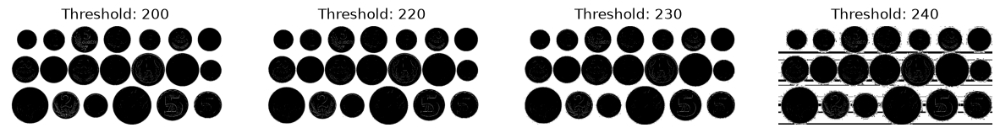

In [17]:
show_threshold_images(image_hsv[:,:,1], [200, 220, 230, 240])

Wybrałem kanał S ponieważ on bardzo dobrze oddziela nam wartosciami tło od monet co widac na histogramie. 

Przetestuj opracowany powyżej algorytm na poniższym obrazie z wyraźnym zaszumieniem. Co się zmienia i dlaczego? Uzupełnij potok przetwarzania o odszumianie.

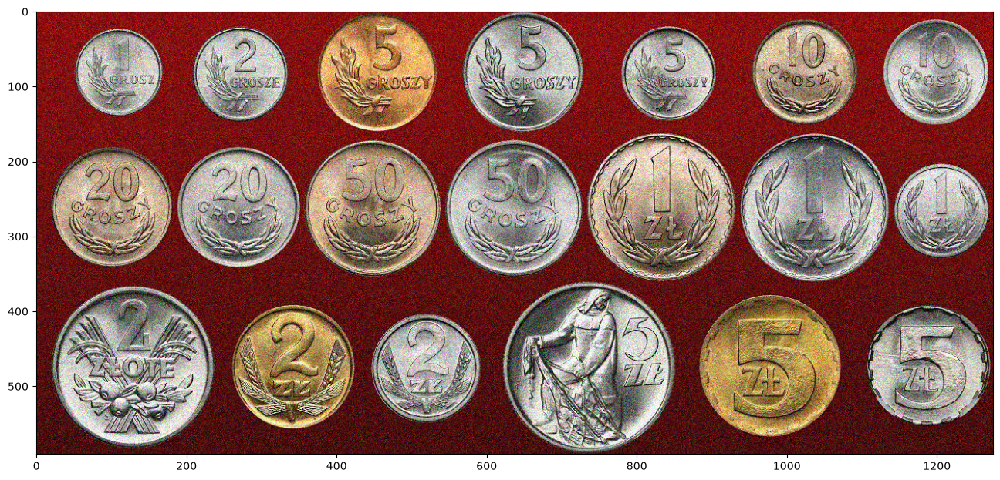

In [22]:
monety_kolor_szum = cv2.imread('../Materialy/Monety_kolor_szum.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor_szum[..., ::-1]);

Text(0.5, 1.0, 'Value')

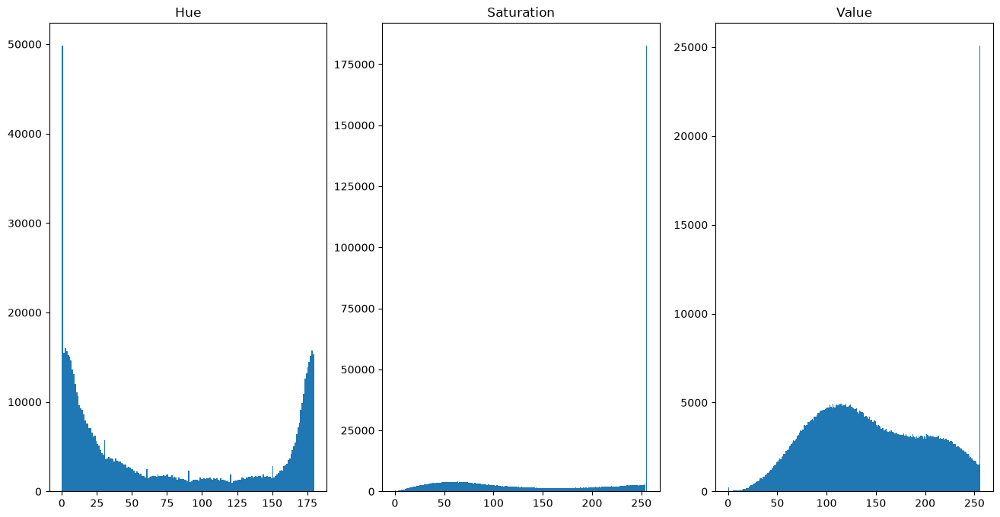

In [23]:
image_hsv_szum = cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2HSV)

_, (h, s, v) = plt.subplots(1,3, figsize=(16,8))

h.hist(image_hsv_szum[:,:,0].flatten(), bins=180, range=(0, 180))
h.set_title('Hue')
s.hist(image_hsv_szum[:,:,1].flatten(), bins=256, range=(0, 256))
s.set_title('Saturation')
v.hist(image_hsv_szum[:,:,2].flatten(), bins=256, range=(0, 256))
v.set_title('Value')

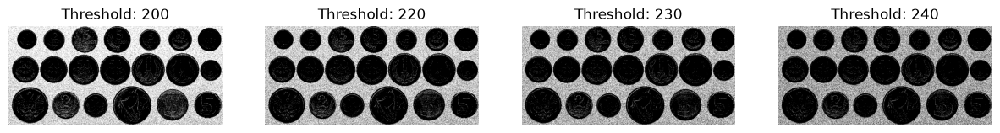

In [24]:
show_threshold_images(image_hsv_szum[:,:,1], [200, 220, 230, 240])

Szum spłaszczył i poszerzył histogram S: wąski pik tła rozlał się na szeroki zakres wartości i nachodzi na wartości monet. Przez to przy każdym progu część pikseli tła spada poniżej progu, a część pikseli monet go przekracza. W binaryzacji widać to jako ziarno w tle i na monetach.

Text(0.5, 1.0, 'Value')

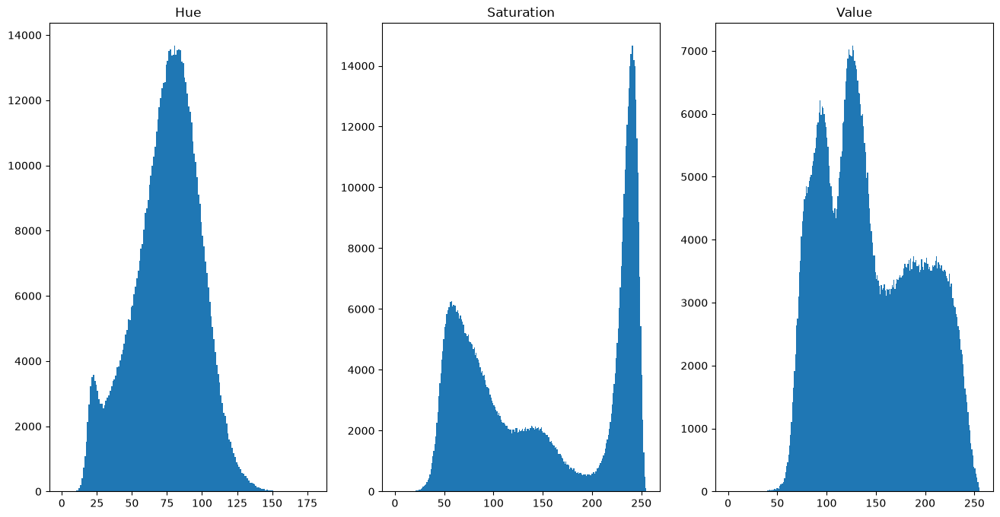

In [41]:
image_hsv_denoised = cv2.GaussianBlur(image_hsv_szum, (5, 5), 0)
_, (h, s, v) = plt.subplots(1,3, figsize=(16,8))

h.hist(image_hsv_denoised[:,:,0].flatten(), bins=180, range=(0, 180))
h.set_title('Hue')
s.hist(image_hsv_denoised[:,:,1].flatten(), bins=256, range=(0, 256))
s.set_title('Saturation')
v.hist(image_hsv_denoised[:,:,2].flatten(), bins=256, range=(0, 256))
v.set_title('Value')


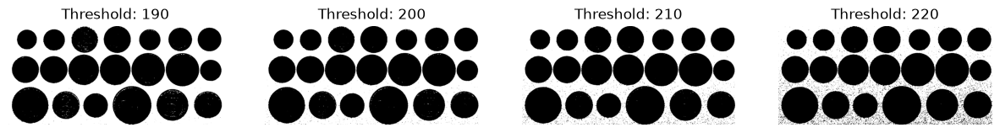

In [42]:
show_threshold_images(image_hsv_denoised[:,:,1], [190, 200, 210, 220])

Odszumienie kanału S przywróciło wyraźne garby w histogramie, ale nie odtworzyło wąskiego piku tła. Wartości tła są rozrzucone wokół pierwotnego garba, a część z nich leży poniżej poprzedniego progu. Dlatego musimy obniżyć próg, żeby tło nie było klasyfikowane jako monety.

##### Zad. 3: Tekst

W tym przypadku należy wyodrębnić litery od bardzo nierównomiernie oświetlonego tła. Skorzystaj z binaryzacji metodą Otsu. Zastosuj binaryzację w sposób lokalny (oknem przesuwnym). Jaki wpływ ma rozmiar okna na jakość binaryzacji? Jak przesuwać okno?

_(Pełna punktacja za zadanie wymaga własnoręcznej implementacji okna przesuwnego - samo Otsu możesz wziąć z OpenCV. Użycie zamiast tego_ `cv2.adaptiveThreshold` _liczone będzie jako pół zadania, ale jedynie po demonstracji zrozumienia tej metody.)_

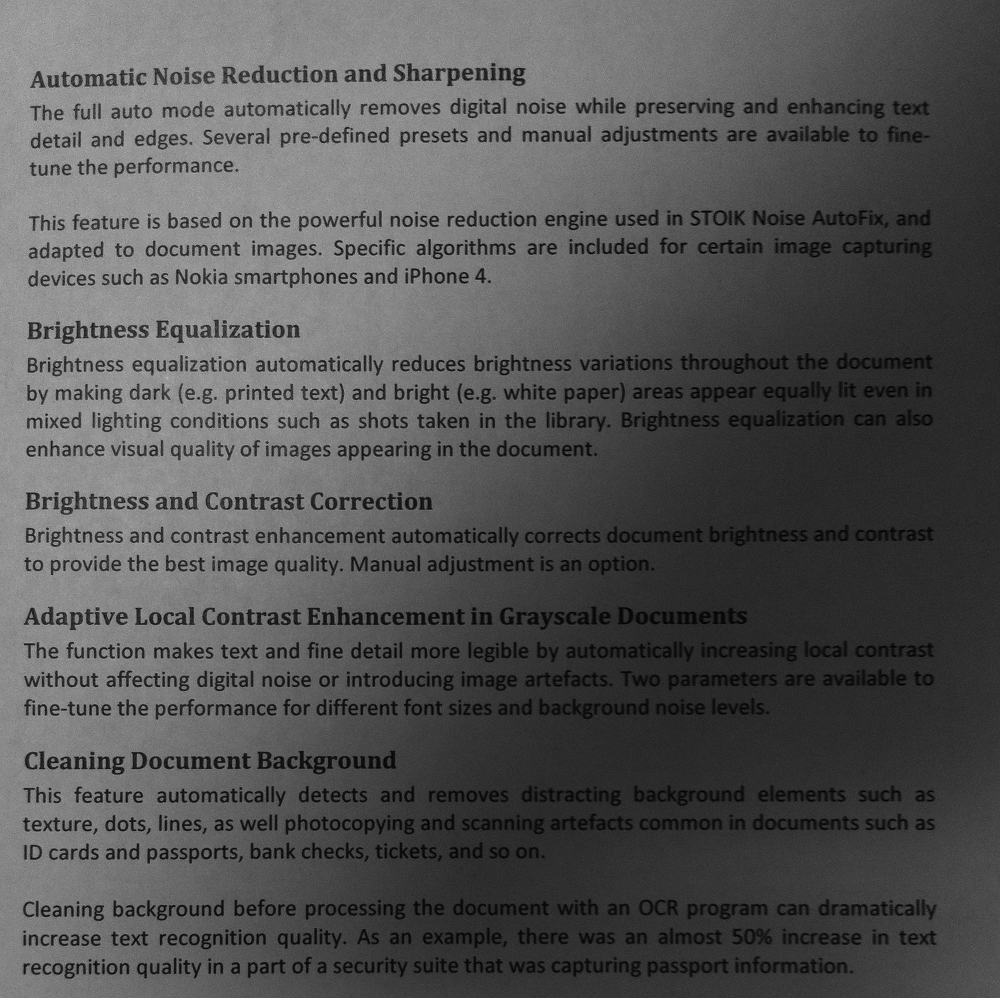

In [29]:
tekst = cv2.imread('../Materialy/Tekst1.bmp')
Image.fromarray(cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY))

Rozwiązanie:

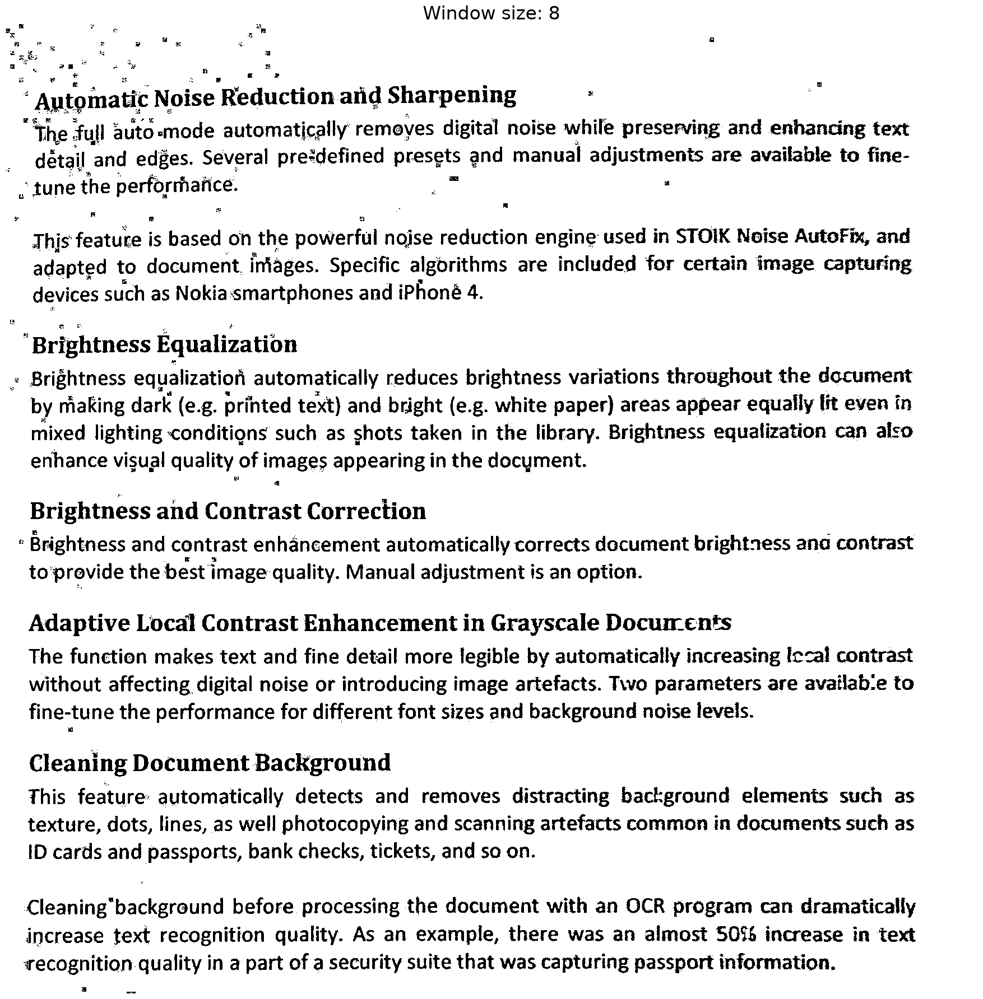

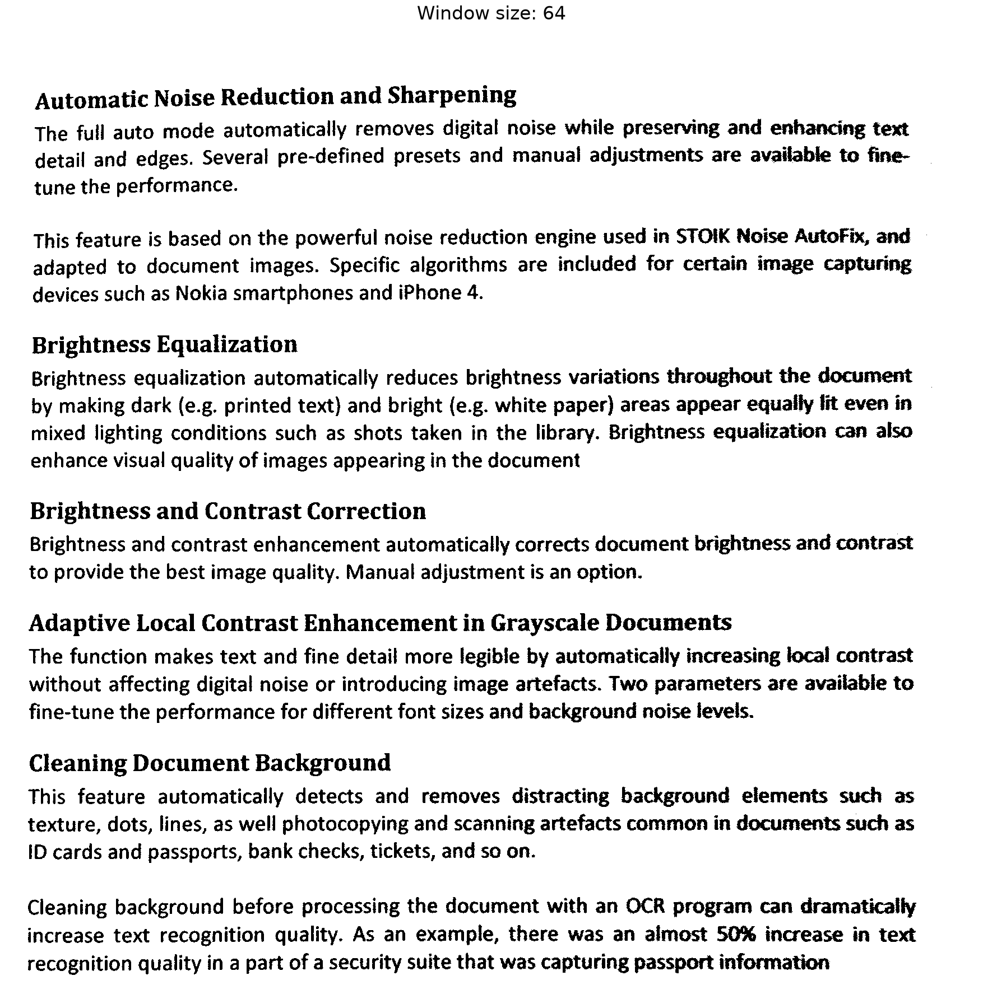

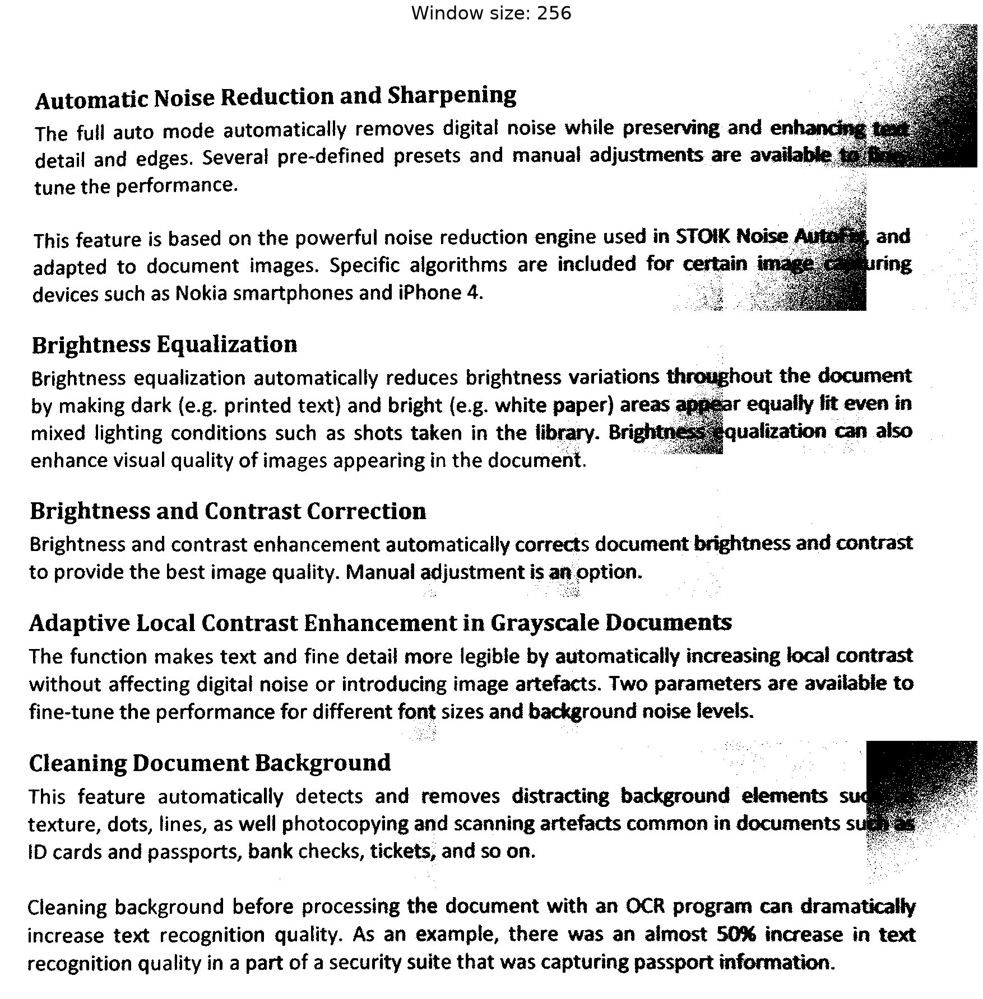

In [62]:
def local_otsu(image, window_size, min_contrast=13):
    height, width = image.shape
    thresholded_image = np.zeros_like(image)

    for y in range(0, height, window_size):
        for x in range(0, width, window_size):
            y_end = min(y + window_size, height)
            x_end = min(x + window_size, width)
            local_window = image[y:y_end, x:x_end]

            local_thresh, _ = cv2.threshold(local_window, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            dark = local_window[local_window <= local_thresh]
            bright = local_window[local_window > local_thresh]

            # Mały kontrast między klasami Otsu -> okno to samo tło
            if dark.size == 0 or bright.size == 0 or bright.mean() - dark.mean() < min_contrast:
                thresholded_image[y:y_end, x:x_end] = 255
                continue

            thresholded_image[y:y_end, x:x_end] = (local_window > local_thresh).astype(np.uint8) * 255

    return Image.fromarray(thresholded_image)

window_sizes = [8, 64, 256]
text_gray = cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY)
dpi = 100
h, w = text_gray.shape

for window_size in window_sizes:
    fig = plt.figure(figsize=(w / dpi, h / dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(local_otsu(text_gray, window_size), cmap='gray', interpolation='nearest', vmin=0, vmax=255)
    ax.set_title(f'Window size: {window_size}', fontsize=24)
    ax.axis('off')
    plt.show()

Otsu zakłada, że w oknie występują dwie klasy pikseli (litery i tło), a rozmiar okna decyduje, czy to założenie jest spełnione. Małe okno (8 px) często zawiera tylko jedną klasę: okno leżące w całości w literze ma mały kontrast i zostaje uznane za tło (biały kwadrat w literze), a w oknie z samym tłem kilka pojedynczych pikseli szumu wystarcza, by kontrast przekroczył próg. Otsu dzieli wtedy na siłę sam szum papieru i większość okna staje się czarna (czarne kwadraciki na tle). Średnie okno (64 px) zawiera fragmenty liter razem z tłem, a oświetlenie jest w nim w przybliżeniu stałe, więc daje najlepszy wynik. Duże okno (256 px) obejmuje obszary o różnym oświetleniu, przez co na przejściach z jasnej do ciemnej części jeden próg nie rozdziela liter od tła, a wynik zbliża się do globalnego Otsu.

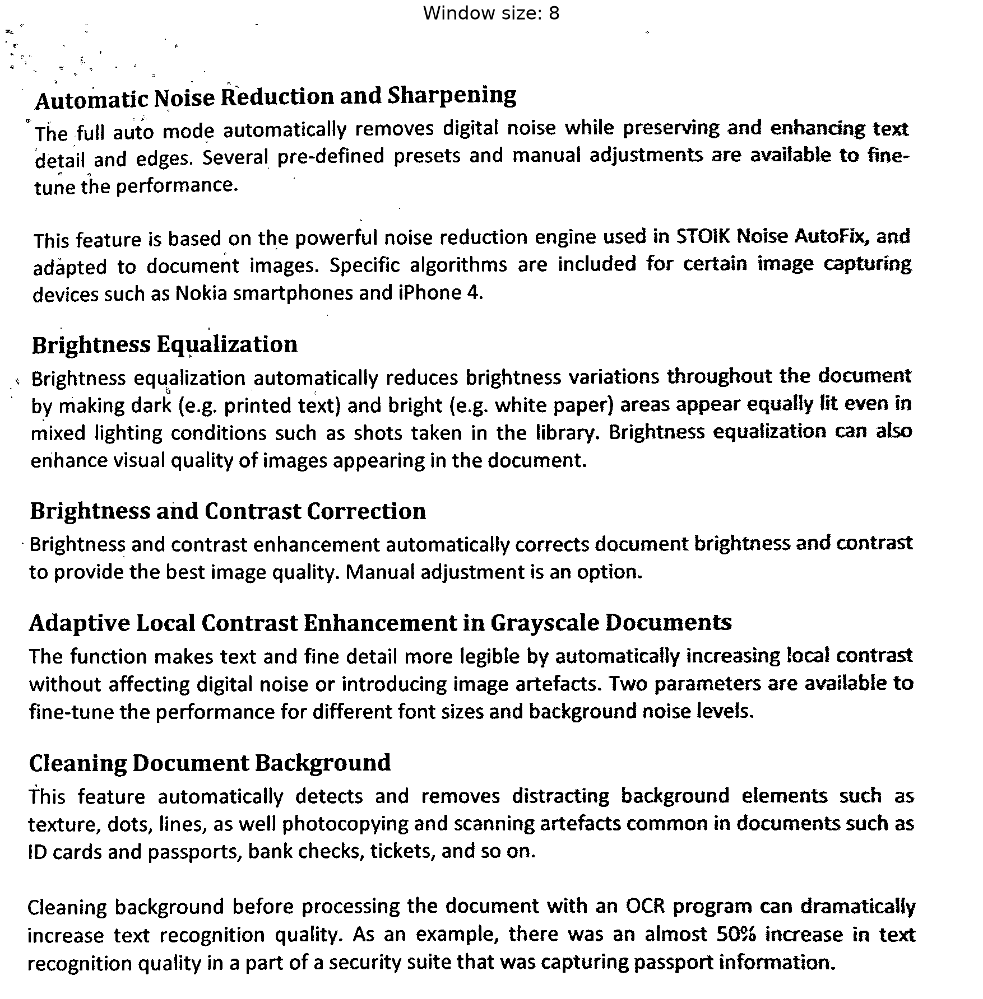

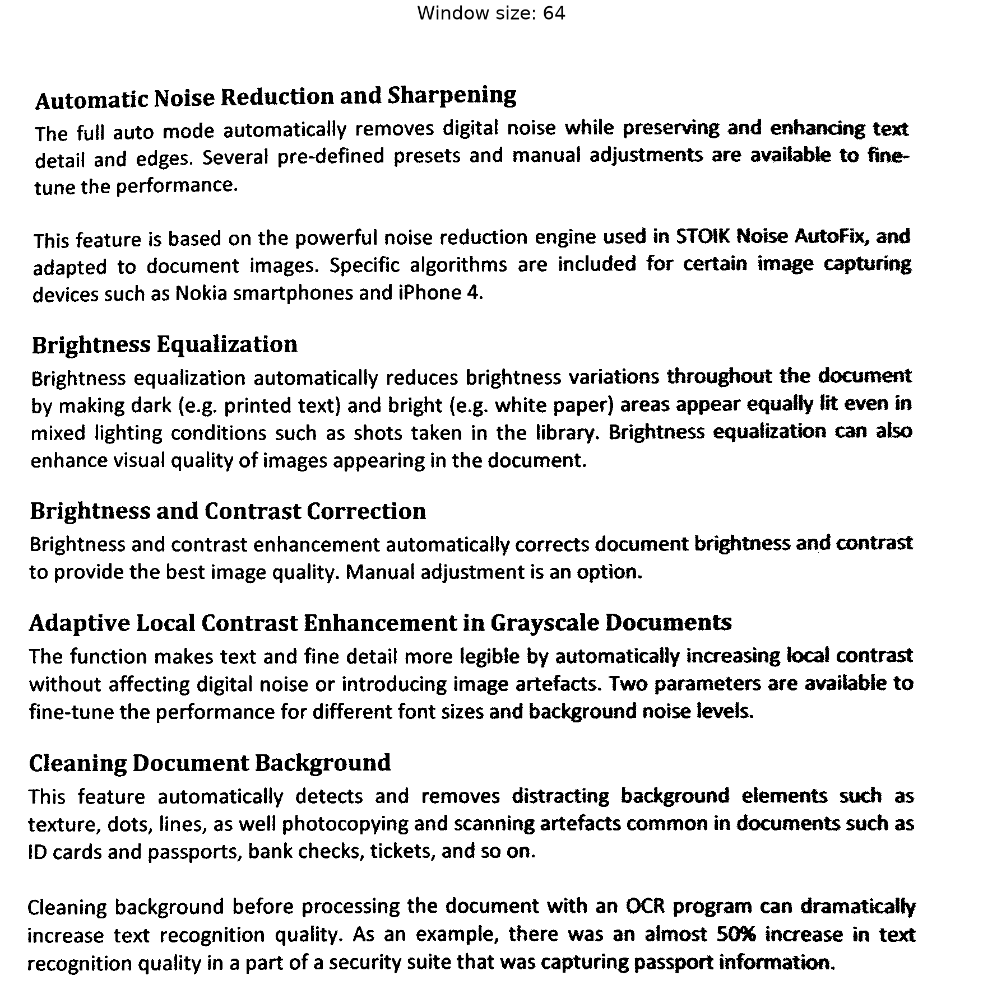

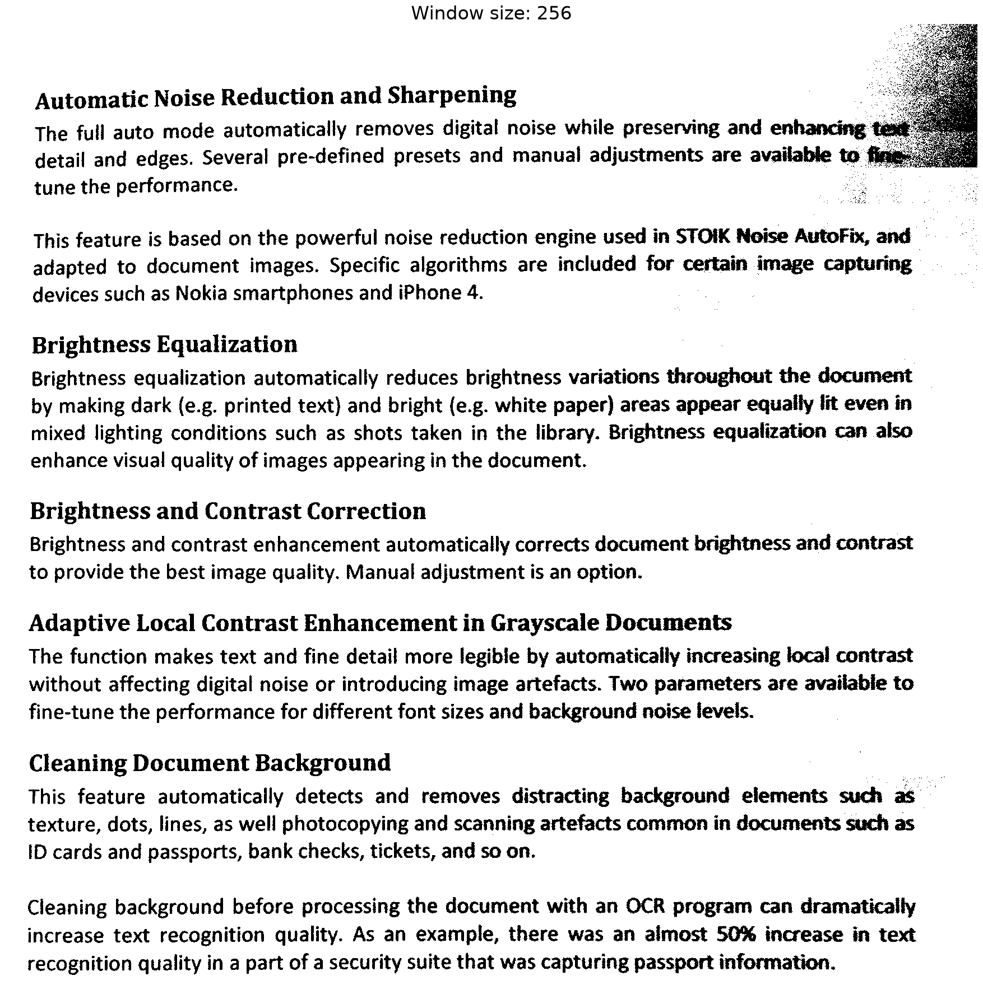

In [67]:
def local_otsu(image, window_size, step=None, min_contrast=13):
    if step is None:
        step = window_size                     # brak nakładania
    height, width = image.shape
    votes = np.zeros((height, width), np.float32)   # ile okien uznało piksel za jasny
    counts = np.zeros((height, width), np.float32)  # ile okien pokryło piksel

    # Pozycje okien; ostatnie okno dosunięte do krawędzi, żeby pokryć cały obraz
    ys = list(range(0, max(height - window_size, 0) + 1, step))
    xs = list(range(0, max(width - window_size, 0) + 1, step))
    if ys[-1] + window_size < height: ys.append(height - window_size)
    if xs[-1] + window_size < width: xs.append(width - window_size)

    for y in ys:
        for x in xs:
            local_window = image[y:y + window_size, x:x + window_size]
            counts[y:y + window_size, x:x + window_size] += 1

            local_thresh, _ = cv2.threshold(local_window, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            dark = local_window[local_window <= local_thresh]
            bright = local_window[local_window > local_thresh]

            # Mały kontrast między klasami Otsu -> okno to samo tło (głos na jasny)
            if dark.size == 0 or bright.size == 0 or bright.mean() - dark.mean() < min_contrast:
                votes[y:y + window_size, x:x + window_size] += 1
                continue

            votes[y:y + window_size, x:x + window_size] += (local_window > local_thresh)

    # Głosowanie większościowe
    thresholded_image = ((votes / counts) >= 0.5).astype(np.uint8) * 255
    return Image.fromarray(thresholded_image)

window_sizes = [8, 64, 256]
text_gray = cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY)
dpi = 100
h, w = text_gray.shape

for window_size in window_sizes:
    fig = plt.figure(figsize=(w / dpi, h / dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(local_otsu(text_gray, window_size,step=window_size//4), cmap='gray', interpolation='nearest', vmin=0, vmax=255)
    ax.set_title(f'Window size: {window_size}', fontsize=24)
    ax.axis('off')
    plt.show()

Okno przesuwamy z krokiem mniejszym niż jego rozmiar (np. ¼ okna), tak aby okna się nakładały. Każdy piksel jest wtedy oceniany przez kilka okien, a wynik ustalamy głosowaniem większościowym. Dzięki temu pojedyncze okno, w którym Otsu źle podzieliło piksele (np. samo tło albo samo wnętrze litery), zostaje przegłosowane przez sąsiednie okna. Znikają też skokowe zmiany progu na granicach kafelków. Mniejszy krok poprawia jakość, ale liczba okien rośnie z kwadratem odwrotności kroku, więc czas obliczeń szybko rośnie. Krok co 1 piksel jest najdokładniejszy, ale niepraktycznie wolny.